In [1]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [2]:
#importo le libreirie necessarie per analizzare i dati
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import difflib
import re

In [3]:
#importo i dati dal csv e creo il mio data_set locale
club_df= pd.read_csv('clubs.csv')
club_df

,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,url
0,105,sv-darmstadt-98,Sportverein Darmstadt 1898 e. V.,L1,NaN,30,26.4,11,36.7,1,Merck-Stadion am Böllenfalltor,17810,€-1.60m,NaN,2023,https://www.transfermarkt.co.uk/sv-darmstadt-9...
1,11127,ural-ekaterinburg,FK Ural Yekaterinburg,RU1,NaN,25,28.2,13,52.0,5,Yekaterinburg Arena,23000,€-770k,NaN,2023,https://www.transfermarkt.co.uk/ural-ekaterinb...
2,114,besiktas-istanbul,Beşiktaş Jimnastik Kulübü,TR1,NaN,32,27.4,16,50.0,13,Tüpraş Stadyumu,42590,€-14.50m,NaN,2023,https://www.transfermarkt.co.uk/besiktas-istan...
3,12,as-rom,Associazione Sportiva Roma,IT1,NaN,26,27.4,17,65.4,17,Olimpico di Roma,73261,+€65.20m,NaN,2023,https://www.transfermarkt.co.uk/as-rom/startse...
4,148,tottenham-hotspur,Tottenham Hotspur Football Club,GB1,NaN,29,26.2,21,72.4,22,Tottenham Hotspur Stadium,62062,€-130.40m,NaN,2023,https://www.transfermarkt.co.uk/tottenham-hots...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,68608,cf-os-belenenses,CF Os Belenenses,PO1,NaN,30,25.7,5,16.7,0,Estádio do Restelo,19980,+-0,NaN,2017,https://www.transfermarkt.co.uk/cf-os-belenens...
422,724,fc-volendam,Football Club Volendam,NL1,NaN,29,22.8,14,48.3,3,Kras Stadion,7384,+€1.80m,NaN,2023,https://www.transfermarkt.co.uk/fc-volendam/st...
423,800,atalanta-bergamo,Atalanta Bergamasca Calcio S.p.a.,IT1,NaN,25,27.2,17,68.0,15,Gewiss Stadium,21747,+€87.00m,NaN,2023,https://www.transfermarkt.co.uk/atalanta-berga...
424,979,moreirense-fc,Moreirense Futebol Clube,PO1,NaN,26,26.0,17,65.4,2,Estádio C. J. de Almeida Freitas,6153,€-2.05m,NaN,2023,https://www.transfermarkt.co.uk/moreirense-fc/...


In [4]:
#tramite la descrizione riesco ad osservare che il valore di mercato e i nomi degli allenatori non vengono mai menzionati, quindi sono
#eliminabili. Il numero minimo di giocatori esteri non corrisponde alla percentuale di giocatori esteri (0 e 2.4%). Il numero di
#giocatori delle squadre è come minimo a 0, quindi probabilmente valore nullo su cui bisogna fare approfondimenti.
#E' inoltre necessario controllare se con 'giocatori della nazionale' si intende giocatori che giocano nella nazionale dello Stato della
#squadra o in una qualsiasi nazionale (es Toro squadra italiana, giocatore che gioca in nazionale può essere:
#italiano (nazionale italiana)
#estero (nazionale esetera))

club_df.describe()

,club_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_seats,coach_name,last_season
count,426.000000,0.0,426.000000,388.000000,426.000000,379.000000,426.000000,426.000000,0.0,426.000000
mean,5314.525822,NaN,24.403756,25.704639,10.983568,45.227968,4.788732,24284.410798,NaN,2020.830986
std,11752.013818,NaN,8.817703,1.596598,6.726748,19.941673,5.083071,17132.848095,NaN,3.207283
min,3.000000,NaN,0.000000,18.300000,0.000000,2.400000,0.000000,0.000000,NaN,2012.000000
25%,421.000000,NaN,24.000000,24.700000,6.000000,30.800000,1.000000,11024.500000,NaN,2019.000000
50%,1139.500000,NaN,27.000000,25.700000,12.000000,46.700000,3.000000,20046.000000,NaN,2023.000000
75%,3415.750000,NaN,29.000000,26.900000,16.000000,58.000000,7.000000,32798.000000,NaN,2023.000000
max,83678.000000,NaN,41.000000,29.700000,31.000000,100.000000,22.000000,81365.000000,NaN,2023.000000


In [5]:
club_df.shape

(426, 16)

In [6]:
#Il tipo del nome del coach è float, tipo molto strano per questo dato, motivo per il quale probabilmente non sono stati inseriti
#valori
club_df.dtypes

club_id                      int64
club_code                   object
name                        object
domestic_competition_id     object
total_market_value         float64
squad_size                   int64
average_age                float64
foreigners_number            int64
foreigners_percentage      float64
national_team_players        int64
stadium_name                object
stadium_seats                int64
net_transfer_record         object
coach_name                 float64
last_season                  int64
url                         object
dtype: object

In [7]:
club_df.columns

Index(['club_id', 'club_code', 'name', 'domestic_competition_id',
       'total_market_value', 'squad_size', 'average_age', 'foreigners_number',
       'foreigners_percentage', 'national_team_players', 'stadium_name',
       'stadium_seats', 'net_transfer_record', 'coach_name', 'last_season',
       'url'],
      dtype='object')

In [8]:
#Come dati interessanti mantengo id, nome, numero di giocatori che sono importanti per la squadra, per l'analisi dei giocatori
#delle squadre uso invece età media, numero di giocatori esteri con la percentuale, i giocatori che si trovano nella nazionale
#e il saldo netto dei trasferimenti
df=club_df[['club_id','name','squad_size','average_age','foreigners_number','foreigners_percentage', 'national_team_players','net_transfer_record']]
df=df.set_index('club_id').sort_values(by='name')
df=df[~df.duplicated()]
df

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
89,1. FC Union Berlin,28,27.5,16,57.1,11,€-29.90m
39,1. Fußball- und Sportverein Mainz 05,25,27.0,12,48.0,6,+€14.55m
3,1. Fußball-Club Köln,31,25.6,8,25.8,6,+€200k
2036,1. Fußballclub Heidenheim 1846,28,26.2,6,21.4,1,€-2.30m
4,1.FC Nuremberg,33,25.2,7,21.2,2,+€2.63m
...,...,...,...,...,...,...,...
126,Çaykur Rizespor Kulübü,36,24.6,18,50.0,6,€-3.41m
24245,Ümraniyespor,12,25.8,3,30.0,1,+-0
6890,İstanbul Başakşehir Futbol Kulübü,34,26.1,16,47.1,6,+-0


In [9]:
#Nel dataset dei games, abbiamo osservato che era presente una sola squadra 'Футбольный клуб "Локомотив" Москва' (come mostrato nella tabella
#sopra) che presenta un nome in cirillico. Abbiamo deciso di cancellare il dato perché difficilmente rappresentabile.
#Controlliamo che anche in questo dataset è l'unica squadra. E' effettivamente l'unica squadra, quindi la eliminiamo

#funzione usata per trovare i testi in cirillico
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
    
#Squadre di calcio con il nome in cirillico
df_filtered=df[df['name'].apply(contains_cyricclic)]
df_filtered

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
932,"Футбольный клуб ""Локомотив"" Москва",27,24.5,3,11.1,9,+€3.48m


In [10]:
df = df[~df['name'].isin(df_filtered['name'])]
df

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
89,1. FC Union Berlin,28,27.5,16,57.1,11,€-29.90m
39,1. Fußball- und Sportverein Mainz 05,25,27.0,12,48.0,6,+€14.55m
3,1. Fußball-Club Köln,31,25.6,8,25.8,6,+€200k
2036,1. Fußballclub Heidenheim 1846,28,26.2,6,21.4,1,€-2.30m
4,1.FC Nuremberg,33,25.2,7,21.2,2,+€2.63m
...,...,...,...,...,...,...,...
8838,Zirka Kropyvnytskyi,7,27.4,0,NaN,0,+-0
126,Çaykur Rizespor Kulübü,36,24.6,18,50.0,6,€-3.41m
24245,Ümraniyespor,12,25.8,3,30.0,1,+-0


In [11]:
#ricontrolliamo che non sia più presente
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
df_filtered=df[df['name'].apply(contains_cyricclic)]
df_filtered

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,


In [12]:
df.columns

Index(['name', 'squad_size', 'average_age', 'foreigners_number',
       'foreigners_percentage', 'national_team_players',
       'net_transfer_record'],
      dtype='object')

In [13]:
df.describe()

,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players
count,425.000000,387.000000,425.000000,378.000000,425.000000
mean,24.397647,25.707752,11.002353,45.318254,4.778824
std,8.827193,1.597486,6.723480,19.890388,5.084941
min,0.000000,18.300000,0.000000,2.400000,0.000000
25%,24.000000,24.700000,6.000000,30.850000,1.000000
50%,27.000000,25.700000,12.000000,46.700000,3.000000
75%,29.000000,26.900000,16.000000,58.150000,7.000000
max,41.000000,29.700000,31.000000,100.000000,22.000000


In [14]:
#Provo a vedere se oltra al valore 0 nel numero di giocatori nella squadra (valore nullo) sono presenti altri outliner.
#La dimensione delle squadre ha diversi outliner sia come minimo che come massimo
df=df[df['squad_size']>0]
df.describe()

,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players
count,387.000000,387.000000,387.000000,378.000000,387.000000
mean,26.793282,25.707752,12.082687,45.318254,5.248062
std,4.608356,1.597486,6.047171,19.890388,5.092458
min,3.000000,18.300000,0.000000,2.400000,0.000000
25%,25.000000,24.700000,8.000000,30.850000,1.000000
50%,27.000000,25.700000,13.000000,46.700000,4.000000
75%,29.000000,26.900000,16.000000,58.150000,8.000000
max,41.000000,29.700000,31.000000,100.000000,22.000000


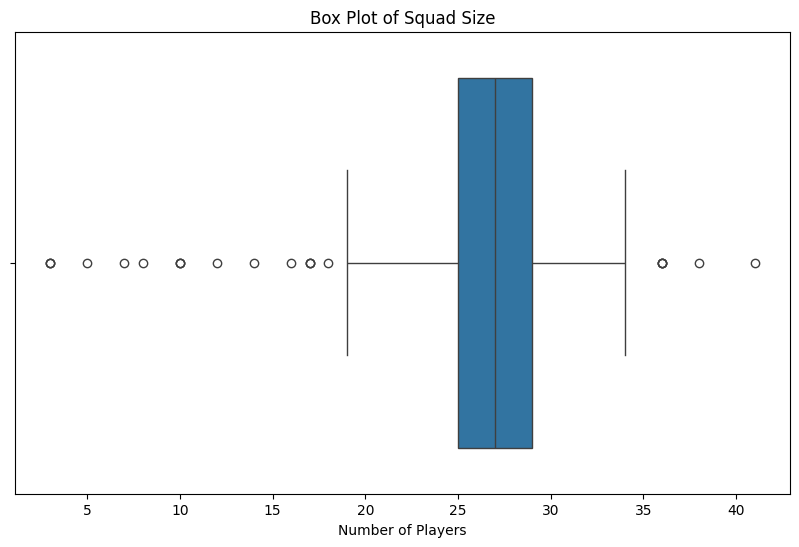

In [15]:
#Prima di eliminare i dati dal nostro database (essendo outliers) ne ho rappresentato un grafico utilizzando un boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['squad_size'])
plt.title("Box Plot of Squad Size")
plt.xlabel("Number of Players")
plt.show()

In [16]:
#Elimino tutte le squadre con meno di 11 giocatori poiché è il numero minimo di giocatori in una squadra, quindi lo considero
#come limite base
df=df[(df['squad_size']>10)]
df.describe()

,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players
count,378.000000,378.000000,378.000000,373.000000,378.000000
mean,27.275132,25.753439,12.338624,45.570509,5.370370
std,3.395029,1.514528,5.877317,19.818546,5.089686
min,12.000000,21.000000,0.000000,2.400000,0.000000
25%,25.000000,24.800000,8.000000,31.300000,1.000000
50%,27.000000,25.700000,13.000000,46.700000,4.000000
75%,29.000000,26.900000,16.000000,58.600000,8.000000
max,41.000000,29.700000,31.000000,100.000000,22.000000


In [17]:
#Cerco gli outlier superiori
out=df[(df['squad_size']>29)]
out.describe()

,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players
count,84.000000,84.000000,84.000000,84.000000,84.000000
mean,31.619048,25.473810,15.011905,47.691667,6.071429
std,2.087858,1.370174,6.314058,19.876766,5.138528
min,30.000000,22.600000,1.000000,2.400000,0.000000
25%,30.000000,24.300000,11.000000,36.625000,2.000000
50%,31.000000,25.450000,15.000000,49.200000,5.000000
75%,32.000000,26.400000,19.250000,58.950000,8.000000
max,41.000000,28.800000,31.000000,86.100000,22.000000


In [18]:
#Considero come limite superiore 35 ed elimino tutti gli outliers superiori
df=df[(df['squad_size']<35)]
df.describe()

,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players
count,372.000000,372.000000,372.000000,367.000000,372.000000
mean,27.115591,25.771774,12.258065,45.537330,5.370968
std,3.169952,1.518310,5.779233,19.724285,5.114012
min,12.000000,21.000000,0.000000,3.300000,0.000000
25%,25.000000,24.800000,8.000000,31.150000,1.000000
50%,27.000000,25.700000,13.000000,46.700000,4.000000
75%,29.000000,26.900000,16.000000,58.600000,8.000000
max,34.000000,29.700000,27.000000,100.000000,22.000000


In [19]:
#Controllando i valori nulli possiamo vedere che 'foreigners_percentage' ha valore nullo quando 'foreigners_number' è 0,
#quindi lo possiamo sostituire con 0
Nan=df[df['foreigners_percentage'].isna()]
Nan

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
19771,Akhisarspor,14,21.0,0,NaN,0,+€5k
4128,Amkar Perm,26,26.0,0,NaN,0,+-0
20,Bursaspor,26,21.4,0,NaN,0,+-0
2292,Elazigspor,28,25.3,0,NaN,0,+-0
63007,LNZ Cherkasy,26,28.7,0,NaN,0,€-150k


In [20]:
df.loc[:, 'foreigners_percentage'] = df['foreigners_percentage'].fillna(0.0)
Nan=df[df['foreigners_percentage'].isna()]
Nan

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,


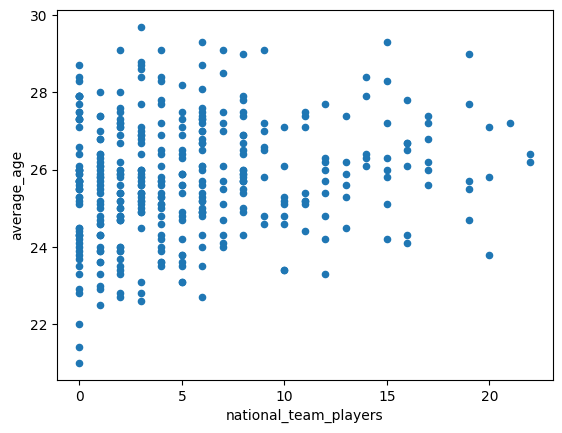

In [21]:
#Analizzo se il numero di giocatori in nazionale è proprozionale con l'età media, ma non sembra sia così
ax=df.plot(kind='scatter',x='national_team_players', y='average_age')

In [22]:
#posso utilizzare anche una matrice di causalità per cercare una correlazione
df[['national_team_players','average_age']].dropna().corr()

,national_team_players,average_age
national_team_players,1.000000,0.164855
average_age,0.164855,1.000000


In [23]:
#ora analizzo quali sono i club con il net_transfer più alto e più basso. I primi possono essere utili perché, avendo molte
#finanze possono investire sui giocatori, i secondi invece potrebbero essere squadre intente a vendere giocatori di valore

df_sorted = df.sort_values(by='net_transfer_record')
df_sorted=df_sorted[~df_sorted['net_transfer_record'].isna()] #devo eliminare i valori nulli
df_sorted
#a quanto pare sono rimasti dei valori nulli/sconosciuti '+-0', quindi li elimino

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
6992,ZAO FK Chornomorets Odessa,21,25.7,5,23.8,0,+-0
2727,Oud-Heverlee Leuven,27,24.9,16,59.3,3,+-0
833,Denizlispor,27,25.8,3,11.1,1,+-0
1436,SC Beira-Mar,26,26.6,8,30.8,0,+-0
133,SC Cambuur Leeuwarden,16,23.1,4,25.0,3,+-0
...,...,...,...,...,...,...,...
1435,Go Ahead Eagles,27,24.7,10,37.0,2,€-850k
2441,Athlitiki Enosi Konstantinoupoleos,31,28.3,22,71.0,15,€-9.35m
354,Yellow-Red Koninklijke Voetbalclub Mechelen,27,24.8,9,33.3,2,€-900k


In [24]:
df_sorted=df_sorted[df_sorted['net_transfer_record']!='+-0']
df_sorted

,name,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,net_transfer_record
club_id,,,,,,,
1531,Elche CF,18,27.3,5,27.8,0,+€1.00m
1244,CD Leganés,23,28.6,8,34.8,3,+€1.00m
49702,FK Nizhny Novgorod,25,26.1,9,36.0,4,+€1.03m
1245,Königliche Allgemeine Sportvereinigung Eupen,29,24.3,19,65.5,7,+€1.10m
338,Futbolniy Klub Dynamo Kyiv,27,24.3,3,11.1,8,+€1.20m
...,...,...,...,...,...,...,...
1435,Go Ahead Eagles,27,24.7,10,37.0,2,€-850k
2441,Athlitiki Enosi Konstantinoupoleos,31,28.3,22,71.0,15,€-9.35m
354,Yellow-Red Koninklijke Voetbalclub Mechelen,27,24.8,9,33.3,2,€-900k


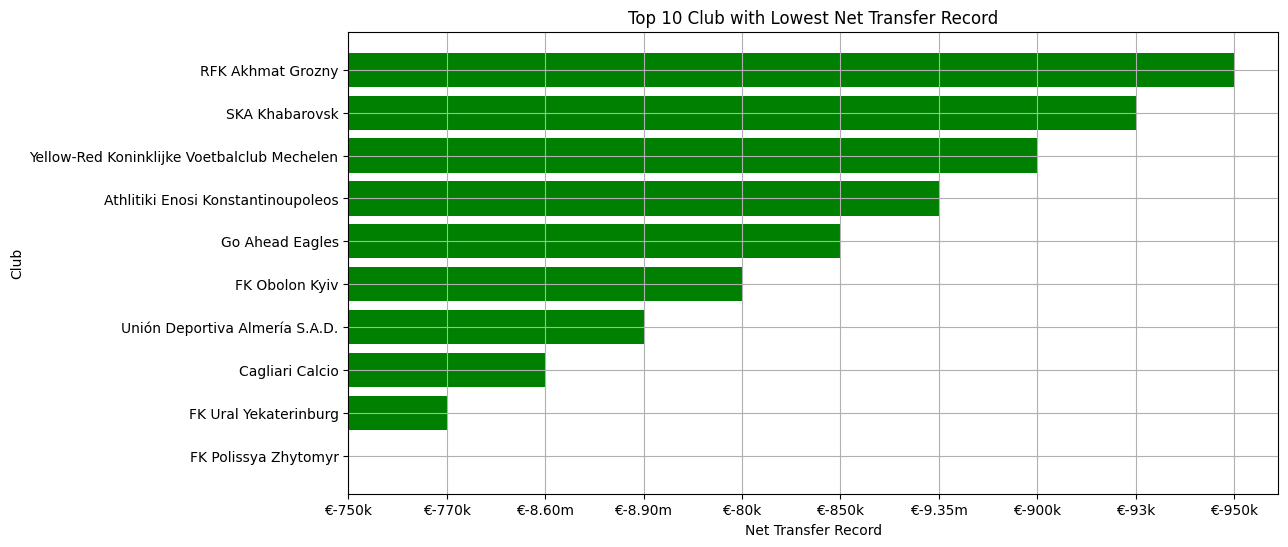

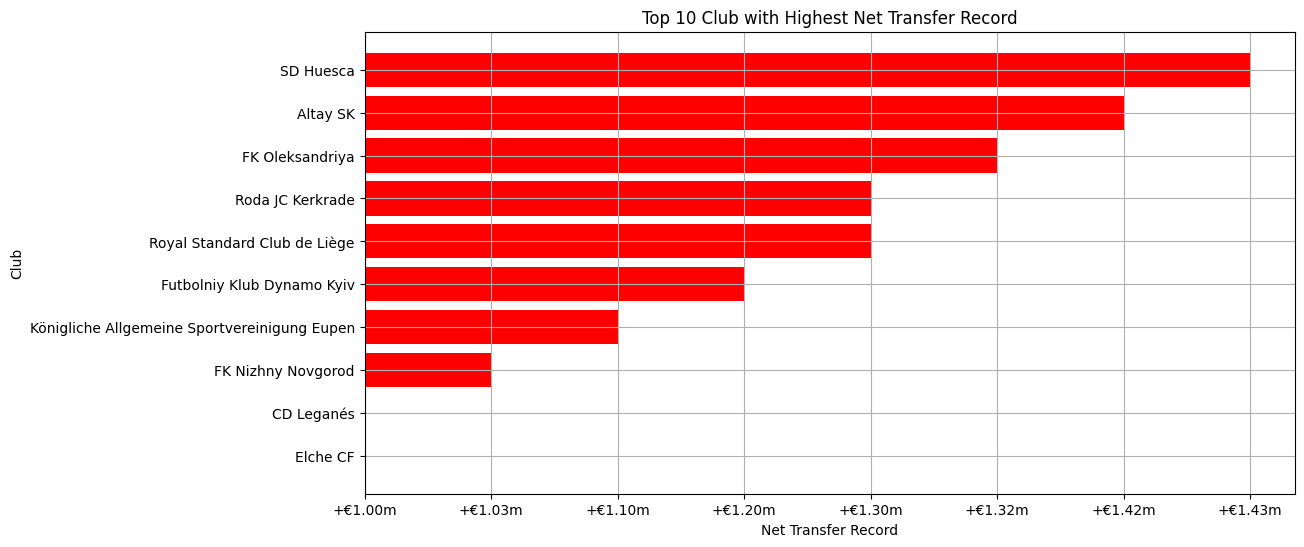

In [25]:
highest_net_transfer = df_sorted.head(10)
lowest_net_transfer = df_sorted.tail(10)

plt.figure(figsize=(12, 6))
plt.barh(lowest_net_transfer['name'], lowest_net_transfer['net_transfer_record'], color='green')
plt.xlabel('Net Transfer Record')
plt.ylabel('Club')
plt.title('Top 10 Club with Lowest Net Transfer Record')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.barh(highest_net_transfer['name'], highest_net_transfer['net_transfer_record'], color='red')
plt.xlabel('Net Transfer Record')
plt.ylabel('Club')
plt.title('Top 10 Club with Highest Net Transfer Record')
plt.grid(True)
plt.show()

In [26]:
#voglio provare ad analizzare i giocatori delle nazionali che fanno parte del club
player_df=pd.read_csv('players.csv')
player_df.columns
#tramite i giocatori non si può scoprire se fanno parte della nazionale

Index(['player_id', 'first_name', 'last_name', 'name', 'last_season',
       'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'market_value_in_eur',
       'highest_market_value_in_eur', 'contract_expiration_date', 'agent_name',
       'image_url', 'url', 'current_club_domestic_competition_id',
       'current_club_name'],
      dtype='object')

In [46]:
#provo a cercare tra le varie competizioni quelle europee a cui partecipano le nazionali
competition_df=pd.read_csv('competitions.csv')
competition_df=competition_df[competition_df['country_id']==-1]
competition_df=competition_df[['competition_id','competition_code', 'name', 'sub_type', 'type']]
competition_df

,competition_id,competition_code,name,sub_type,type
6,USC,uefa-super-cup,uefa-super-cup,uefa_super_cup,other
8,EL,europa-league,europa-league,europa_league,international_cup
17,ELQ,europa-league-qualifikation,europa-league-qualifikation,europa_league_qualifying,international_cup
20,ECLQ,uefa-europa-conference-league-qualifikation,uefa-europa-conference-league-qualifikation,uefa_europa_conference_league_qualifiers,international_cup
26,CL,uefa-champions-league,uefa-champions-league,uefa_champions_league,international_cup
31,KLUB,fifa-klub-wm,fifa-klub-wm,fifa_club_world_cup,other
37,CLQ,uefa-champions-league-qualifikation,uefa-champions-league-qualifikation,uefa_champions_league_qualifying,international_cup


In [44]:
#creno un nuovo set per trovare i club con le loro competizioni e provo a fare il merge 
df_competitions=club_df[['club_id','name','domestic_competition_id']].copy()
df_competitions.rename(columns={'domestic_competition_id':'competition_id'}, inplace=True)
merge_df=pd.merge(competition_df, df_competitions, on='competition_id', how='inner')
merge_df
#nessun club partecipa alle competizioni europee

,competition_id,competition_code,name_x,sub_type,type,club_id,name_y


In [47]:
#come possiamo vedere tutte le competizioni sono nazionali, quindi usando solo i dati statici non possiamo ricavare l'informazione
#all'interno di Games
type_club_df=club_df[['domestic_competition_id']].drop_duplicates()
type_club_df

,domestic_competition_id
0,L1
1,RU1
2,TR1
3,IT1
4,GB1
5,BE1
6,DK1
8,NL1
10,GR1
13,PO1
